## Group 4 — Predicting 30-day readmission of diabetic patients

Applying and Interpreting Machine Learning - group project

**Team**: Szilárd Bagi, Petra Hilbert, Natália Szabó, Linda Truong

**Question**: Can we predict at **discharge**, which diabetic patients will be **readmitted within 30 days**, so that staff can give extra follow-up (a call, an early appointment) to the patients who need it most?

**Data**: UCI Diabetes 130-US Hospitals 1999–2008 (diabetic_data.csv). One row = one hospital encounter.

The notebook has 5 blocks:  
1. Data preparation: data checks, outcome, features, split into train and test (grouped by patient)  
2. Model building: metric, 2 baselines, 3 models (logistic regression, random forest, boosting) tuned by cross-validation  
3. Validation: compare the models by cross-validation, choose the model and the threshold (no test data)  
4. Performance evaluation: test set, used once, with confidence intervals  
5. Error analysis and interpretation: where the model fails, what drives it, limits

**Main choices:**  
- outcome = readmitted within 30 days (about 11% of encounters)  
- split = 80/20, grouped by patient  
- metric = AUPRC, plus precision and recall at a cost-based threshold  
- baselines = flag nobody, and a clinical rule.

Running time: about 7 minutes

  ## 1. Data preparation  
  ### 1.1 Import packages and settings

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve
from sklearn.calibration import calibration_curve

seed = 42            # one seed for everything
cost_ratio = 5       # assumption: a missed readmission costs 5 times as much as an unnecessary follow-up
flag_share = 0.20    # assumption: staff can follow up with the 20% highest-risk patients
n_trees = 100        # trees in the random forest
n_boot = 1000        # bootstrap repetitions for the confidence intervals

np.random.seed(seed)

### 1.2 Load the data and check it

In the raw file '?' means missing. The text 'None' in the two lab-test columns is a real answer ("test not done"), so we do not treat it as missing.

In [2]:
raw = pd.read_csv("diabetic_data.csv", na_values=["?"], keep_default_na=False, low_memory=False) # low_memory=False: read the file in one go, so there is no mixed-type warning

# Table 1: how big is the data, and how often does a patient appear?
per_patient = raw.groupby("patient_nbr").size()                       # number of encounters of each patient
size_table = pd.Series({
    "encounters (rows)": len(raw),
    "columns": raw.shape[1],
    "patients": len(per_patient),
    "encounter_id is unique": raw["encounter_id"].is_unique,
    "patients with more than 1 encounter": f"{(per_patient > 1).mean():.1%}",
    "most encounters of one patient": per_patient.max(),
}, name="value").to_frame()
print("Table 1. Size of the data")
display(size_table)

# Table 2: encounters per patient. Many patients come back, so a random split would put the same patient in train AND test.
print("Table 2. Number of encounters per patient")
bins = pd.cut(per_patient, [0, 1, 2, 3, 5, 100], labels=["1", "2", "3", "4-5", "6+"])
display(bins.value_counts().sort_index().rename("patients").to_frame())

Table 1. Size of the data


,value
encounters (rows),101766
columns,50
patients,71518
encounter_id is unique,True
patients with more than 1 encounter,23.5%
most encounters of one patient,40


Table 2. Number of encounters per patient


,patients
1,54745
2,10434
3,3328
4-5,2138
6+,873


In [3]:
# Table 3: missing values (only the columns that have any)
missing = raw.isna().sum()
missing = missing[missing > 0]
missing_table = pd.DataFrame({"missing": missing, "share": (missing / len(raw)).round(3)}).sort_values("share", ascending=False)
print("Table 3. Missing values per column")
display(missing_table)

# Table 4: the raw outcome column
print("Table 4. Outcome column 'readmitted' (raw)")
display(pd.DataFrame({
    "encounters": raw["readmitted"].value_counts(), 
    "share": raw["readmitted"].value_counts(normalize=True).round(3)}))

Table 3. Missing values per column


,missing,share
weight,98569,0.969
medical_specialty,49949,0.491
payer_code,40256,0.396
race,2273,0.022
diag_3,1423,0.014
diag_2,358,0.004
diag_1,21,0.000


Table 4. Outcome column 'readmitted' (raw)


,encounters,share
readmitted,,
NO,54864,0.539
>30,35545,0.349
<30,11357,0.112


What the checks tell us: many patients appear more than once (so we must **group by patient**), weight is 97% missing (we drop it), and medical_specialty / payer_code have many missing values (we treat "missing" as its own category).

### 1.3 Outcome and exclusions

- Outcome: 1 = readmitted within 30 days (<30), 0 = readmitted later or never.
- Patients who died or went to hospice cannot be readmitted, so we remove them (discharge_disposition_id: 11, 13, 14, 19, 20, 21). Three rows with unknown gender are removed too.
- groups = patient ID. We use it only to keep one patient on one side of every split. It is not a feature.

In [34]:
# check: how many rows have each gender value, and how many rows will we remove?
print(raw["gender"].value_counts())
print("Died / hospice rows:", raw["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21]).sum())

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
Died / hospice rows: 2423


In [35]:
# remove patients who died / went to hospice, and the rows with unknown gender
df = raw[~raw["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]
df = df[df["gender"] != "Unknown/Invalid"].copy()

y = (df["readmitted"] == "<30").astype(int)          # outcome: readmitted within 30 days
# alternative (balanced) outcome: y = (df["readmitted"] != "NO").astype(int)
groups = df["patient_nbr"]                           # used only for the grouped splits

# Table 5: what the exclusions did
print("Table 5. Data before and after the exclusions")
display(pd.DataFrame({"encounters": [len(raw), len(df)], "patients": [raw["patient_nbr"].nunique(), groups.nunique()],
                      "share readmitted <30": [(raw["readmitted"] == "<30").mean().round(4), y.mean().round(4)]},
                     index=["raw data", "after exclusions"]))
print("Only about 11% of encounters are readmitted within 30 days, so the outcome is highly imbalanced and accuracy would be misleading.")

Table 5. Data before and after the exclusions


,encounters,patients,share readmitted <30
raw data,101766,71518,0.1116
after exclusions,99340,69987,0.1139


Only about 11% of encounters are readmitted within 30 days, so the outcome is highly imbalanced and accuracy would be misleading.


### 1.4 Feature construction

The prediction moment is **discharge**, so we only use what is known then. We do not use readmitted (the outcome), patient_nbr (grouping only), encounter_id (can encode time), weight (97% missing), examide / citoglipton (same value in every row).

The steps below only recode and count, row by row. Nothing is learned from the data, so doing them before the split is not leakage. (Anything that *is* learned from data, such as scaling, comes after the split.)

In [6]:
features = pd.DataFrame(index=df.index)

# demographics (race is NOT a model input. We keep it only to check fairness in Block 5)
features["age_num"] = df["age"].map({f"[{a}-{a+10})": a + 5 for a in range(0, 100, 10)})    # middle of the age bracket
features["gender"] = df["gender"]
features["race"] = df["race"].fillna("Unknown")

# admission (missing = own category)
features["admission_type"] = df["admission_type_id"].map({1: "Emergency", 2: "Urgent", 3: "Elective"}).fillna("Other")
features["admission_source"] = df["admission_source_id"].map({1: "Referral", 2: "Referral", 3: "Referral", 7: "Emergency room"}).fillna("Other")
features["payer_code"] = df["payer_code"].fillna("Unknown")
features["medical_specialty"] = df["medical_specialty"].fillna("Unknown")

# earlier visits in the previous 12 months, and the stay that is ending (numbers are used as they are)
for col in ["number_outpatient", "number_emergency", "number_inpatient",
            "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses"]:
    features[col] = df[col]
features["discharge_group"] = df["discharge_disposition_id"].map(
    {1: "Home", 6: "Home with health service", 8: "Home with health service",
     3: "Nursing / long-term care", 4: "Nursing / long-term care", 23: "Nursing / long-term care", 24: "Nursing / long-term care",
     22: "Rehabilitation"}).fillna("Other")

# main diagnosis: ICD-9 code -> broad group (V and E codes and missing codes become "Other / missing")
icd = np.floor(pd.to_numeric(df["diag_1"], errors="coerce"))                  # 250.83 -> 250
icd_bins = [0, 139, 239, 249, 250, 389, 459, 519, 579, 629, 709, 739, 799, 999]
icd_labels = ["Infectious", "Neoplasms", "Endocrine (not diabetes)", "Diabetes", "Mental / nervous system / other", "Circulatory",
              "Respiratory", "Digestive", "Genitourinary", "Pregnancy / skin", "Musculoskeletal", "Symptoms / congenital", "Injury"]
features["diag_1"] = pd.cut(icd, icd_bins, labels=icd_labels, include_lowest=True).astype("object").fillna("Other / missing")

# lab tests ("None" = not measured) and diabetes medication
features["max_glu_serum"] = df["max_glu_serum"].replace({"None": "Not measured"})
features["A1Cresult"] = df["A1Cresult"].replace({"None": "Not measured"})
for col in ["insulin", "change", "diabetesMed"]:
    features[col] = df[col]

print("Features built:", features.shape[1], "columns (race is only for the fairness check)")

Features built: 22 columns (race is only for the fairness check)


### 1.5 Dummy columns

Text columns become 0/1 dummy columns (`pd.get_dummies`). Race is left out.

In [33]:
X = pd.get_dummies(features.drop(columns="race"), dtype=int)                 # text -> 0/1 dummies, numbers stay as they are
numeric_cols = list(features.select_dtypes("number").columns)                # the columns that are not dummies
assert X.isna().sum().sum() == 0                                             # no missing values left

# Table 6: the numeric features
print("Table 6. Numeric features")
display(features[numeric_cols].describe().T.round(2)[["mean", "std", "min", "max"]])
print("Columns in the design matrix:", X.shape[1])

Table 6. Numeric features


,mean,std,min,max
age_num,65.74,15.95,5.0,95.0
number_outpatient,0.37,1.27,0.0,42.0
number_emergency,0.20,0.94,0.0,76.0
number_inpatient,0.63,1.26,0.0,21.0
time_in_hospital,4.38,2.97,1.0,14.0
num_lab_procedures,42.91,19.61,1.0,132.0
num_procedures,1.33,1.70,0.0,6.0
num_medications,15.98,8.09,1.0,81.0
number_diagnoses,7.40,1.94,1.0,16.0


Columns in the design matrix: 144


### 1.6 Split into train and test (grouped by patient)

Many patients appear more than once. With a random split, the same patient could be in train and test, and the results would look too good.

So we split by patient. StratifiedGroupKFold with groups = patient_nbr keeps all encounters of a patient together and keeps the share of readmissions similar. With 5 folds, one fold (20%) is the test set.

**From here on, the test set is not used until Block 4.**

In [ ]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
train_idx, test_idx = next(splitter.split(X, y, groups))        # first fold = test set (20%)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.to_numpy()[train_idx], y.to_numpy()[test_idx]
groups_train, groups_test = groups.to_numpy()[train_idx], groups.to_numpy()[test_idx]

assert len(set(groups_train) & set(groups_test)) == 0           # check: no patient is in both sets

# Table 7: the two sets
print("Table 7. Train and test set")
display(pd.DataFrame({"encounters": [len(y_train), len(y_test)], "patients": [len(set(groups_train)), len(set(groups_test))],
                      "share readmitted <30": [y_train.mean().round(4), y_test.mean().round(4)]}, index=["train", "test"]))

Table 7. Train and test set


,encounters,patients,share readmitted <30
train,79473,56036,0.1139
test,19867,13951,0.1139


### 1.7 Preprocessing (training set only)

These steps learn from the data, so we use the **training set only**. The test set gets the same numbers.

1. Drop dummy columns that are almost always 0 (or almost always 1).
2. Standardize the columns for the logistic regression (lasso and ridge depend on the size of the columns). Trees do not need this.

In [ ]:
# 1) drop (almost) constant dummy columns. Counted on the train set only, the same columns are dropped from the test set
dummy_cols = [c for c in X_train.columns if c not in numeric_cols]
n_ones = X_train[dummy_cols].sum()
drop_cols = n_ones[(n_ones < 50) | (n_ones > len(X_train) - 50)].index
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)
print("Dropped", len(drop_cols), "rare dummy columns. Columns left:", X_train.shape[1])

# 2) standardize: mean and SD come from the TRAIN set, then the same numbers are applied to the test set
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

Dropped 43 rare dummy columns. Columns left: 101


### 1.8 Cross-validation folds

All choices (settings, model, threshold) are made with 5-fold cross-validation **inside the training set**. The folds are grouped by patient too, and they are the same for every model.

In [10]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

# CHECK: in every fold, no patient is in both the training part and the validation part
for fold_train, fold_val in cv.split(X_train, y_train, groups_train):
    assert len(set(groups_train[fold_train]) & set(groups_train[fold_val])) == 0
print("5 folds, no patient shared between the training and validation part")

5 folds, no patient shared between the training and validation part


## 2. Model building

### 2.1 Metric and baselines

Only 11% of encounters are readmitted, so accuracy is misleading. We use **AUPRC** (area under the precision-recall curve) instead. A random guess has an AUPRC equal to the share of positives (the base rate).

**Cost of errors:** a missed readmission costs more than an unnecessary follow-up call. We assume it costs `cost_ratio` = 5 times as much (the hospital must set the real number).

**Baselines** (nothing is fitted):

1. Flag nobody (majority class).
2. Clinical rule: flag everyone with at least one inpatient stay in the previous year.

In [11]:
rule_all = (df["number_inpatient"] >= 1).to_numpy()          # the rule uses the raw count
rule_train, rule_test = rule_all[train_idx], rule_all[test_idx]

majority_folds, rule_folds = [], []
for fold_train, fold_val in cv.split(X_train, y_train, groups_train):
    majority_folds.append(y_train[fold_val].mean())                                      # a constant score has AUPRC = base rate
    rule_folds.append(average_precision_score(y_train[fold_val], rule_train[fold_val]))
majority_folds, rule_folds = np.array(majority_folds), np.array(rule_folds)

print("Clinical rule flags", round(rule_train.mean(), 3), "of the training encounters")
print("  precision:", round(y_train[rule_train].mean(), 3), "  recall:", round(y_train[rule_train].sum() / y_train.sum(), 3))
print("CV AUPRC majority class:", round(majority_folds.mean(), 4), "(= base rate)")
print("CV AUPRC clinical rule: ", round(rule_folds.mean(), 4))

Clinical rule flags 0.332 of the training encounters
  precision: 0.17   recall: 0.496
CV AUPRC majority class: 0.1139 (= base rate)
CV AUPRC clinical rule:  0.1417


### 2.2 Logistic regression (lasso and ridge)

The model estimates the probability of readmission from a weighted sum of the features. A penalty keeps the weights small: the **lasso** sets many of them to exactly 0, the **ridge** only shrinks them.

`C` is the inverse of the penalty strength: a smaller `C` means a stronger penalty. We try several values for both penalties and keep the best one by cross-validation.

lasso  C = 0.001   CV AUPRC = 0.197
lasso  C = 0.003   CV AUPRC = 0.2102
lasso  C = 0.01   CV AUPRC = 0.2124
lasso  C = 0.03   CV AUPRC = 0.212
lasso  C = 0.1   CV AUPRC = 0.2114
ridge  C = 0.001   CV AUPRC = 0.211
ridge  C = 0.003   CV AUPRC = 0.2111
ridge  C = 0.01   CV AUPRC = 0.211
ridge  C = 0.03   CV AUPRC = 0.2109
ridge  C = 0.1   CV AUPRC = 0.2109
Selected: ('lasso', 0.01)


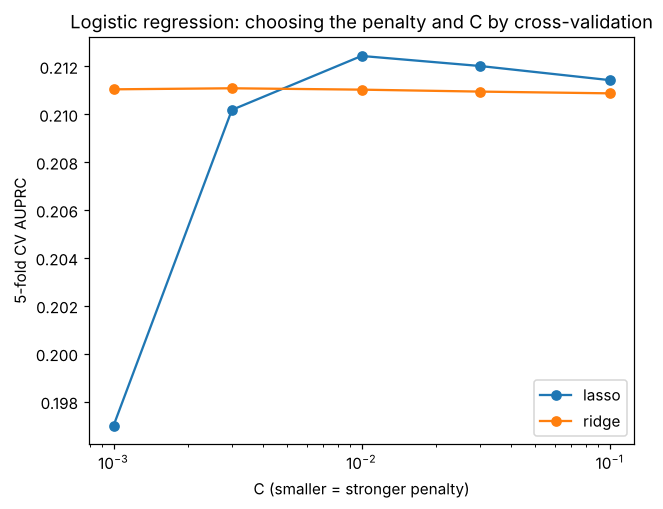

In [12]:
C_values = [0.001, 0.003, 0.01, 0.03, 0.1]
logit_scores = {}          # (penalty, C) -> AUPRC in each of the 5 folds

for penalty in ["lasso", "ridge"]:
    for C in C_values:
        if penalty == "lasso":
            model = LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=5000)     # l1_ratio=1 -> lasso
        else:
            model = LogisticRegression(C=C, max_iter=5000)                                     # default penalty -> ridge
        scores = cross_val_score(model, X_train_s, y_train, cv=cv, groups=groups_train, scoring="average_precision", n_jobs=-1)
        logit_scores[(penalty, C)] = scores
        print(penalty, " C =", C, "  CV AUPRC =", round(scores.mean(), 4))

best_logit = max(logit_scores, key=lambda key: logit_scores[key].mean())
print("Selected:", best_logit)

# figure: CV AUPRC for every C
for penalty in ["lasso", "ridge"]:
    plt.plot(C_values, [logit_scores[(penalty, C)].mean() for C in C_values], marker="o", label=penalty)
plt.xscale("log")
plt.xlabel("C (smaller = stronger penalty)")
plt.ylabel("5-fold CV AUPRC")
plt.title("Logistic regression: choosing the penalty and C by cross-validation")
plt.legend()
plt.show()

### 2.3 Random forest

A random forest averages many deep trees. Each tree is built on a random sample of the rows and, at each split, a random subset of the features. It finds non-linear effects and interactions by itself. We tune two settings:

- `min_samples_leaf`: smallest allowed leaf. Larger means simpler trees.
- `max_features`: how many features are tried at each split.

The number of trees is not tuned (more trees only take longer). This cell takes about 2 minutes.

max_features = 15   min_samples_leaf = 5   CV AUPRC = 0.2211
max_features = 15   min_samples_leaf = 30   CV AUPRC = 0.2221
max_features = 30   min_samples_leaf = 5   CV AUPRC = 0.2202
max_features = 30   min_samples_leaf = 30   CV AUPRC = 0.2226
Selected (min_samples_leaf, max_features): (30, 30)


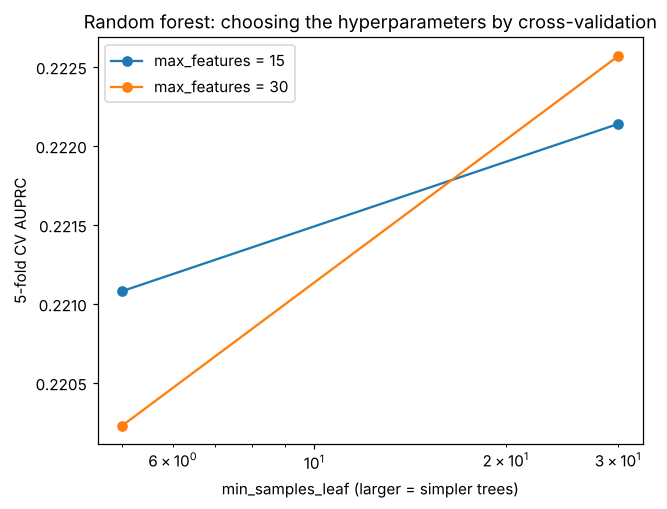

In [13]:
leaf_sizes = [5, 30]
max_features_values = [15, 30]
rf_scores = {}             # (min_samples_leaf, max_features) -> AUPRC in each of the 5 folds

for mf in max_features_values:
    for leaf in leaf_sizes:
        rf = RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=leaf, max_features=mf, random_state=seed, n_jobs=-1)
        scores = cross_val_score(rf, X_train, y_train, cv=cv, groups=groups_train, scoring="average_precision")
        rf_scores[(leaf, mf)] = scores
        print("max_features =", mf, "  min_samples_leaf =", leaf, "  CV AUPRC =", round(scores.mean(), 4))

best_rf = max(rf_scores, key=lambda key: rf_scores[key].mean())
print("Selected (min_samples_leaf, max_features):", best_rf)

# figure: CV AUPRC for every combination
for mf in max_features_values:
    plt.plot(leaf_sizes, [rf_scores[(leaf, mf)].mean() for leaf in leaf_sizes], marker="o", label="max_features = " + str(mf))
plt.xscale("log")
plt.xlabel("min_samples_leaf (larger = simpler trees)")
plt.ylabel("5-fold CV AUPRC")
plt.title("Random forest: choosing the hyperparameters by cross-validation")
plt.legend()
plt.show()

### 2.4 Gradient boosting

Boosting builds many small trees one after another, and each new tree fixes the mistakes of the earlier ones. We use scikit-learn's `HistGradientBoostingClassifier`. We tune two settings:

- `learning_rate`: how much each tree changes the prediction (small means careful).
- `max_depth`: how complex each tree is.

learning_rate = 0.05   max_depth = 3   CV AUPRC = 0.2212
learning_rate = 0.05   max_depth = 5   CV AUPRC = 0.2243
learning_rate = 0.1   max_depth = 3   CV AUPRC = 0.2225
learning_rate = 0.1   max_depth = 5   CV AUPRC = 0.2244
Selected (learning_rate, max_depth): (0.1, 5)


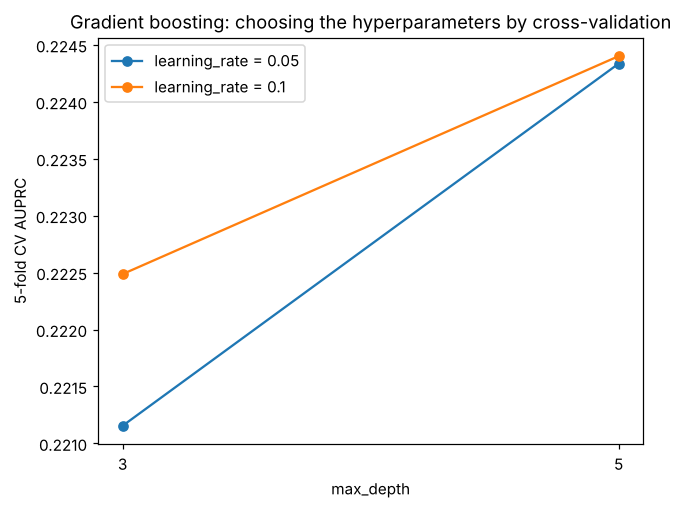

In [14]:
learning_rates = [0.05, 0.1]
depths = [3, 5]
boost_scores = {}          # (learning_rate, max_depth) -> AUPRC in each of the 5 folds

for lr in learning_rates:
    for depth in depths:
        boost = HistGradientBoostingClassifier(max_iter=200, learning_rate=lr, max_depth=depth, min_samples_leaf=20,
                                               l2_regularization=10, random_state=seed)
        scores = cross_val_score(boost, X_train, y_train, cv=cv, groups=groups_train, scoring="average_precision")
        boost_scores[(lr, depth)] = scores
        print("learning_rate =", lr, "  max_depth =", depth, "  CV AUPRC =", round(scores.mean(), 4))

best_boost = max(boost_scores, key=lambda key: boost_scores[key].mean())
print("Selected (learning_rate, max_depth):", best_boost)

# figure: CV AUPRC for every combination
for lr in learning_rates:
    plt.plot(depths, [boost_scores[(lr, depth)].mean() for depth in depths], marker="o", label="learning_rate = " + str(lr))
plt.xticks(depths)
plt.xlabel("max_depth")
plt.ylabel("5-fold CV AUPRC")
plt.title("Gradient boosting: choosing the hyperparameters by cross-validation")
plt.legend()
plt.show()

### 2.5 Fit the selected models

We refit each model with its selected settings on the **whole training set**. No test data is used.

In [15]:
if best_logit[0] == "lasso":
    model_logit = LogisticRegression(C=best_logit[1], l1_ratio=1, solver="liblinear", max_iter=5000)
else:
    model_logit = LogisticRegression(C=best_logit[1], max_iter=5000)
model_logit.fit(X_train_s, y_train)

model_rf = RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=best_rf[0], max_features=best_rf[1], random_state=seed, n_jobs=-1)
model_rf.fit(X_train, y_train)

model_boost = HistGradientBoostingClassifier(max_iter=200, learning_rate=best_boost[0], max_depth=best_boost[1], min_samples_leaf=20,
                                             l2_regularization=10, random_state=seed)
model_boost.fit(X_train, y_train)

# the models, the data each one needs (logistic regression uses the standardized columns), and their CV scores
final_models = {"Logistic regression": model_logit, "Random forest": model_rf, "Gradient boosting": model_boost}
inputs_train = {"Logistic regression": X_train_s, "Random forest": X_train, "Gradient boosting": X_train}
inputs_test = {"Logistic regression": X_test_s, "Random forest": X_test, "Gradient boosting": X_test}
cv_scores = {"Baseline: majority class": majority_folds, "Baseline: clinical rule": rule_folds,
             "Logistic regression": logit_scores[best_logit], "Random forest": rf_scores[best_rf], "Gradient boosting": boost_scores[best_boost]}
print("Models fitted:", list(final_models))

Models fitted: ['Logistic regression', 'Random forest', 'Gradient boosting']


## 3. Validation

We choose the model and the threshold here, using only the training set.

### 3.1 Compare the models

All models and both baselines are scored on **the same folds**. The standard deviation shows how much the score changes between folds. We pick the model with the highest mean CV AUPRC.

In [16]:
cv_table = pd.DataFrame(cv_scores, index=["fold 1", "fold 2", "fold 3", "fold 4", "fold 5"])

cv_summary = pd.DataFrame({
    "CV AUPRC (mean)": cv_table.mean(),
    "SD across folds": cv_table.std(ddof=1),
})
cv_summary["lift over base rate"] = cv_summary["CV AUPRC (mean)"] / y_train.mean()

model_names = list(final_models)
selected = max(model_names, key=lambda name: cv_table[name].mean())
print("Base rate (training):", round(y_train.mean(), 4))
print("Selected model (highest CV AUPRC):", selected)

# paired differences fold by fold (same patients in the same fold for both models)
print()
for other in [name for name in model_names if name != selected] + ["Baseline: clinical rule"]:
    diff = cv_table[selected] - cv_table[other]
    print(selected, "minus", other, ": mean", round(diff.mean(), 4), " SD", round(diff.std(ddof=1), 4), " better in", (diff > 0).sum(), "of 5 folds")

print("\nTable 8. Validation performance (training set, 5 grouped folds)")
cv_summary.round(4)

Base rate (training): 0.1139
Selected model (highest CV AUPRC): Gradient boosting

Gradient boosting minus Logistic regression : mean 0.012  SD 0.0043  better in 5 of 5 folds
Gradient boosting minus Random forest : mean 0.0018  SD 0.0012  better in 5 of 5 folds
Gradient boosting minus Baseline: clinical rule : mean 0.0827  SD 0.0133  better in 5 of 5 folds

Table 8. Validation performance (training set, 5 grouped folds)


,CV AUPRC (mean),SD across folds,lift over base rate
Baseline: majority class,0.1139,0.0000,1.0000
Baseline: clinical rule,0.1417,0.0022,1.2442
Logistic regression,0.2124,0.0130,1.8653
Random forest,0.2226,0.0144,1.9543
Gradient boosting,0.2244,0.0153,1.9704


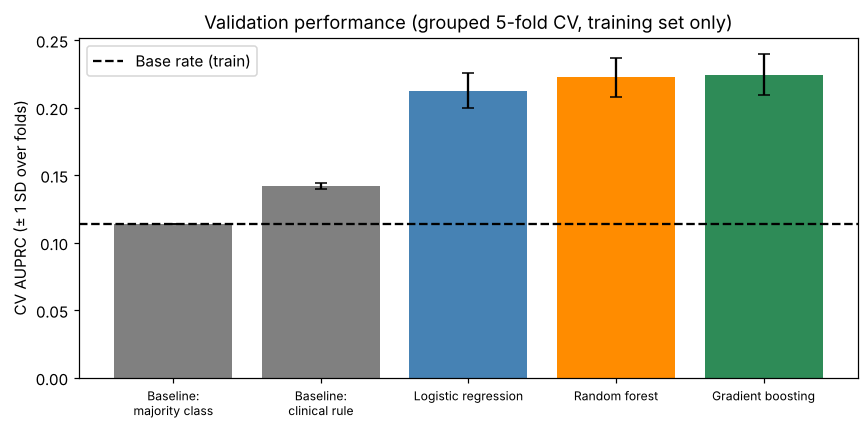

In [17]:
# one colour per model, used in all figures
colors = {"Baseline: majority class": "gray", "Baseline: clinical rule": "gray",
          "Logistic regression": "steelblue", "Random forest": "darkorange", "Gradient boosting": "seagreen"}

plt.figure(figsize=(8, 4))
plt.bar(range(len(cv_summary)), cv_summary["CV AUPRC (mean)"], yerr=cv_summary["SD across folds"], capsize=4,
        color=[colors[name] for name in cv_summary.index])
plt.axhline(y_train.mean(), color="black", linestyle="--", label="Base rate (train)")
plt.xticks(range(len(cv_summary)), [name.replace("Baseline: ", "Baseline:\n") for name in cv_summary.index], fontsize=8)
plt.ylabel("CV AUPRC (± 1 SD over folds)")
plt.title("Validation performance (grouped 5-fold CV, training set only)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 3.2 Choose the threshold

A probability is not yet a decision. We flag a patient when the probability is above a **threshold**. We choose it on **out-of-fold predictions**: each training row is predicted by a model that did not see that patient. We take the threshold with the lowest cost:

$$\text{cost} = \text{cost\_ratio} \cdot FN + FP$$

The cost ratio is an assumption, so the table also shows other values.

In [18]:
# out-of-fold probabilities of the selected model (each training row is predicted by a model that did not see that patient)
oof_probabilities = cross_val_predict(clone(final_models[selected]), inputs_train[selected], y_train,
                                      cv=cv, groups=groups_train, method="predict_proba")[:, 1]
print("Out-of-fold AUPRC of", selected, ":", round(average_precision_score(y_train, oof_probabilities), 4))

thresholds = np.linspace(0.03, 0.5, 95)
rows = []
for ratio in [1, 2, 5, 10, 20]:
    costs = []
    for t in thresholds:
        flagged = oof_probabilities >= t
        FN = (~flagged & (y_train == 1)).sum()                 # missed readmissions
        FP = (flagged & (y_train == 0)).sum()                  # unnecessary follow-ups
        costs.append((ratio * FN + FP) / len(y_train) * 100)   # cost per 100 patients
    t_best = thresholds[np.argmin(costs)]
    flagged = oof_probabilities >= t_best
    rows.append({"cost ratio FN:FP": str(ratio) + ":1", "threshold": t_best, "flagged share": flagged.mean(),
                 "precision": y_train[flagged].mean(), "recall": y_train[flagged].sum() / y_train.sum()})
    if ratio == cost_ratio:
        best_threshold = t_best

# two more cut-offs, also chosen on the training data
cutoff_capacity = np.quantile(oof_probabilities, 1 - flag_share)               # flag the top 20% highest risk
cutoff_rule_share = np.quantile(oof_probabilities, 1 - rule_train.mean())      # flag as many patients as the clinical rule does

print("Chosen threshold for cost ratio", str(cost_ratio) + ":1 =", round(best_threshold, 3))
print("\nTable 9. Best threshold for different cost ratios (training data, out-of-fold)")
pd.DataFrame(rows).set_index("cost ratio FN:FP").round(3)

Out-of-fold AUPRC of Gradient boosting : 0.2232
Chosen threshold for cost ratio 5:1 = 0.165

Table 9. Best threshold for different cost ratios (training data, out-of-fold)


,threshold,flagged share,precision,recall
cost ratio FN:FP,,,,
1:1,0.480,0.003,0.582,0.013
2:1,0.315,0.020,0.401,0.069
5:1,0.165,0.161,0.234,0.330
10:1,0.085,0.595,0.150,0.785
20:1,0.055,0.865,0.125,0.950


## 4. Performance evaluation

The test set is used **once**. Nothing is refitted.

### 4.1 Test performance with uncertainty

We report AUPRC and ROC-AUC with **95% confidence intervals from a bootstrap over patients**. We draw patients (with all their encounters), because encounters of the same patient are not independent.

In [19]:
# predicted probabilities on the test set (the only time the test set is used)
test_probabilities = {}
for name, model in final_models.items():
    test_probabilities[name] = model.predict_proba(inputs_test[name])[:, 1]
test_probabilities["Baseline: clinical rule"] = rule_test.astype(float)
test_probabilities["Baseline: majority class"] = np.zeros(len(y_test))

# bootstrap over patients
patient_codes, patient_ids = pd.factorize(groups_test)
rng = np.random.default_rng(seed)
boot_auprc = {name: [] for name in test_probabilities}
for b in range(n_boot):
    drawn = rng.integers(0, len(patient_ids), len(patient_ids))                       # draw patients with replacement
    weights = np.bincount(drawn, minlength=len(patient_ids))[patient_codes]           # how often each encounter is drawn
    for name, p in test_probabilities.items():
        boot_auprc[name].append(average_precision_score(y_test, p, sample_weight=weights))
boot_auprc = pd.DataFrame(boot_auprc)

order = ["Baseline: majority class", "Baseline: clinical rule"] + model_names
test_summary = pd.DataFrame({
    "Test AUPRC": [average_precision_score(y_test, test_probabilities[name]) for name in order],
    "95% CI low": [boot_auprc[name].quantile(0.025) for name in order],
    "95% CI high": [boot_auprc[name].quantile(0.975) for name in order],
    "Test ROC-AUC": [roc_auc_score(y_test, test_probabilities[name]) for name in order],
    "CV AUPRC (validation)": [cv_summary.loc[name, "CV AUPRC (mean)"] for name in order],
}, index=order)
test_summary["lift over base rate"] = test_summary["Test AUPRC"] / y_test.mean()

print("Test set:", len(y_test), "encounters,", len(patient_ids), "patients, base rate", round(y_test.mean(), 4))
print("\nTable 10. Test performance with 95% confidence intervals")
test_summary.round(4)

Test set: 19867 encounters, 13951 patients, base rate 0.1139

Table 10. Test performance with 95% confidence intervals


,Test AUPRC,95% CI low,95% CI high,Test ROC-AUC,CV AUPRC (validation),lift over base rate
Baseline: majority class,0.1139,0.1082,0.1193,0.5000,0.1139,1.0000
Baseline: clinical rule,0.1420,0.1334,0.1504,0.5932,0.1417,1.2463
Logistic regression,0.2136,0.1955,0.2343,0.6568,0.2124,1.8753
Random forest,0.2239,0.2057,0.2441,0.6661,0.2226,1.9654
Gradient boosting,0.2286,0.2090,0.2503,0.6654,0.2244,2.0070


Gradient boosting minus Logistic regression : difference 0.015  95% CI [0.0069, 0.0228]  better in 100 % of draws
Gradient boosting minus Random forest : difference 0.0047  95% CI [-0.0005, 0.0106]  better in 95 % of draws
Gradient boosting minus Baseline: clinical rule : difference 0.0866  95% CI [0.0726, 0.1032]  better in 100 % of draws


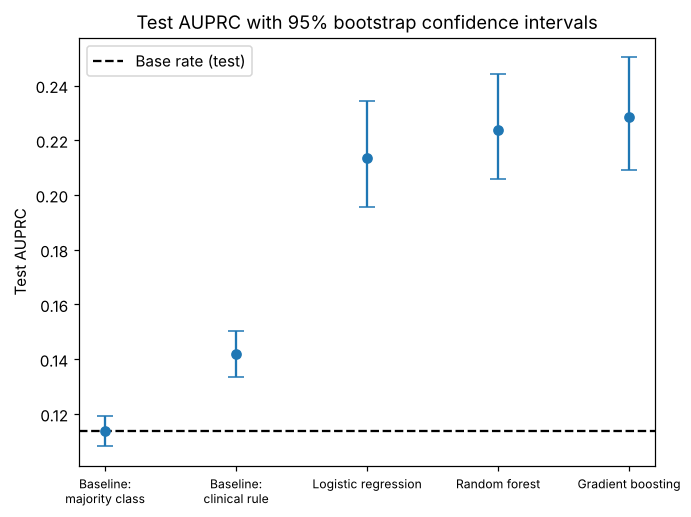

In [20]:
# figure: test AUPRC with 95% bootstrap confidence intervals
x = np.arange(len(test_summary))
plt.errorbar(x, test_summary["Test AUPRC"],
             yerr=[test_summary["Test AUPRC"] - test_summary["95% CI low"], test_summary["95% CI high"] - test_summary["Test AUPRC"]],
             fmt="o", capsize=5)
plt.axhline(y_test.mean(), color="black", linestyle="--", label="Base rate (test)")
plt.xticks(x, [name.replace("Baseline: ", "Baseline:\n") for name in test_summary.index], fontsize=8)
plt.ylabel("Test AUPRC")
plt.title("Test AUPRC with 95% bootstrap confidence intervals")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# is the selected model really better than the others? Paired bootstrap: both are scored on the same drawn patients
for other in [name for name in model_names if name != selected] + ["Baseline: clinical rule"]:
    diff = boot_auprc[selected] - boot_auprc[other]
    point = test_summary.loc[selected, "Test AUPRC"] - test_summary.loc[other, "Test AUPRC"]
    print(selected, "minus", other, ": difference", round(point, 4),
          " 95% CI", diff.quantile([0.025, 0.975]).round(4).tolist(), " better in", round((diff > 0).mean() * 100), "% of draws")

### 4.2 Decisions at the chosen thresholds

The thresholds come from the training data (Block 3). *Cost per 100 patients*: a missed readmission counts as `cost_ratio` follow-ups. Lower is better.

In [21]:
probabilities_test = test_probabilities[selected]

operating_points = {
    "Flag nobody (majority class)":              np.zeros(len(y_test), dtype=bool),
    "Flag everybody":                            np.ones(len(y_test), dtype=bool),
    "Clinical rule (inpatient stay >= 1)":       rule_test,
    selected + ": cost-optimal threshold":       probabilities_test >= best_threshold,
    selected + ": top " + str(int(flag_share * 100)) + "% highest risk": probabilities_test >= cutoff_capacity,
    selected + ": same workload as the rule":    probabilities_test >= cutoff_rule_share,
}

rows = {}
for name, flagged in operating_points.items():
    TP = (flagged & (y_test == 1)).sum()          # flagged and readmitted
    FP = (flagged & (y_test == 0)).sum()          # flagged, not readmitted
    FN = (~flagged & (y_test == 1)).sum()         # not flagged, readmitted (missed)
    TN = (~flagged & (y_test == 0)).sum()
    rows[name] = {"flagged share": flagged.mean(),
                  "precision": TP / (TP + FP) if TP + FP > 0 else np.nan,
                  "recall": TP / (TP + FN),
                  "cost per 100 patients": 100 * (cost_ratio * FN + FP) / len(y_test),
                  "TP": TP, "FP": FP, "FN": FN, "TN": TN}
operating_table = pd.DataFrame(rows).T

print("Table 11. Decisions on the test set")
operating_table.round(3)

Table 11. Decisions on the test set


,flagged share,precision,recall,cost per 100 patients,TP,FP,FN,TN
Flag nobody (majority class),0.000,NaN,0.000,56.954,0.0,0.0,2263.0,17604.0
Flag everybody,1.000,0.114,1.000,88.609,2263.0,17604.0,0.0,0.0
Clinical rule (inpatient stay >= 1),0.337,0.170,0.502,56.320,1136.0,5554.0,1127.0,12050.0
Gradient boosting: cost-optimal threshold,0.166,0.228,0.333,50.838,753.0,2550.0,1510.0,15054.0
Gradient boosting: top 20% highest risk,0.205,0.213,0.384,51.216,868.0,3200.0,1395.0,14404.0
Gradient boosting: same workload as the rule,0.333,0.185,0.543,53.209,1228.0,5396.0,1035.0,12208.0


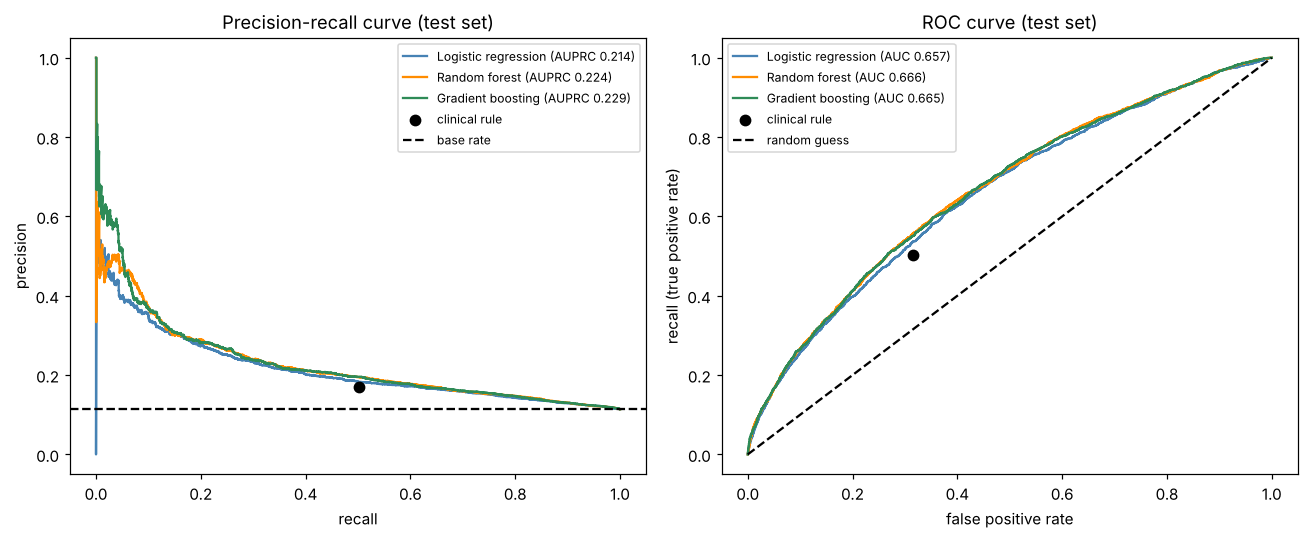

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in model_names:
    precision, recall, _ = precision_recall_curve(y_test, test_probabilities[name])
    axes[0].plot(recall, precision, color=colors[name], label=name + " (AUPRC " + str(round(average_precision_score(y_test, test_probabilities[name]), 3)) + ")")
    fpr, tpr, _ = roc_curve(y_test, test_probabilities[name])
    axes[1].plot(fpr, tpr, color=colors[name], label=name + " (AUC " + str(round(roc_auc_score(y_test, test_probabilities[name]), 3)) + ")")

# the clinical rule is one single point on each curve
rule_row = operating_table.loc["Clinical rule (inpatient stay >= 1)"]
axes[0].scatter(rule_row["recall"], rule_row["precision"], color="black", s=45, zorder=5, label="clinical rule")
axes[1].scatter(rule_row["FP"] / (rule_row["FP"] + rule_row["TN"]), rule_row["recall"], color="black", s=45, zorder=5, label="clinical rule")
axes[0].axhline(y_test.mean(), color="black", linestyle="--", label="base rate")        # random guess
axes[1].plot([0, 1], [0, 1], color="black", linestyle="--", label="random guess")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall curve (test set)")
axes[1].set(xlabel="false positive rate", ylabel="recall (true positive rate)", title="ROC curve (test set)")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Error analysis and interpretation

### 5.1 Where does the model fail?

We look at the selected model at its cost-optimal threshold, for different groups of patients:

- **flagged share:** are some groups flagged more often?
- **recall:** how many of the real readmissions do we catch?
- **calibration:** does the same score mean the same risk everywhere?

Race is not a model input. We only use it here to check for unequal errors. Small groups are noisy, so look at `n` and `positives`.

In [23]:
test_features = features.iloc[test_idx]
flagged_test = probabilities_test >= best_threshold

# the groups we look at
audit = {
    "age": pd.cut(test_features["age_num"], [0, 40, 60, 80, 100], labels=["<40", "40-59", "60-79", "80+"], right=False).astype(str),
    "gender": test_features["gender"],
    "race": test_features["race"].replace({"Other": "Other / unknown", "Unknown": "Other / unknown"}),
    "discharge destination": test_features["discharge_group"],
    "prior inpatient stays": df["number_inpatient"].iloc[test_idx].clip(upper=2).map({0: "0", 1: "1", 2: "2+"}),
}

rows = []
for dimension, labels in audit.items():
    labels = labels.to_numpy()
    for group in sorted(set(labels)):
        in_group = labels == group
        if in_group.sum() < 100:
            continue                                                  # too small to say anything
        yy, pp, ff = y_test[in_group], probabilities_test[in_group], flagged_test[in_group]
        rows.append({"dimension": dimension, "group": group, "n": in_group.sum(), "positives": yy.sum(),
                     "observed rate": yy.mean(), "mean predicted": pp.mean(), "flagged share": ff.mean(),
                     "recall": (ff & (yy == 1)).sum() / yy.sum(),
                     "false positive rate": (ff & (yy == 0)).sum() / (yy == 0).sum(),
                     "precision": yy[ff].mean() if ff.sum() > 0 else np.nan,
                     "AUROC": roc_auc_score(yy, pp)})
subgroups = pd.DataFrame(rows).set_index(["dimension", "group"])

print("Table 12. Errors by patient group (test set, cost-optimal threshold)")
subgroups.round(3)

Table 12. Errors by patient group (test set, cost-optimal threshold)


n  positives  observed rate  mean predicted  flagged share  recall  false positive rate  precision  AUROC
dimension             group                                                                                                                                  
age                   40-59                      5329        533          0.100           0.102          0.144   0.334                0.122      0.233  0.677
                      60-79                      9516       1110          0.117           0.117          0.174   0.338                0.152      0.227  0.657
                      80+                        3808        491          0.129           0.124          0.175   0.281                0.159      0.207  0.630
                      <40                        1214        129          0.106           0.106          0.180   0.481                0.144      0.284  0.740
gender                Female                    10531       1207          0.115           0.114          0.166   0.331                0.145      0.228  0.666
                      Male                       9336       1056          0.113           0.114          0.167   0.335                0.145      0.228  0.665
race                  AfricanAmerican            3758        407          0.108           0.114          0.178   0.342                0.158      0.208  0.662
                      Asian                       114         11          0.096           0.094          0.105   0.091                0.107      0.083  0.701
                      Caucasian                 14826       1731          0.117           0.115          0.168   0.336                0.146      0.234  0.664
                      Hispanic                    378         43          0.114           0.112          0.188   0.419                0.158      0.254  0.754
                      Other / unknown             791         71          0.090           0.093          0.077   0.183                0.067      0.213  0.646
discharge destination Home                      11991       1121          0.093           0.092          0.093   0.228                0.079      0.230  0.654
                      Home with health service   2611        337          0.129           0.128          0.177   0.312                0.157      0.227  0.642
                      Nursing / long-term care   3089        446          0.144           0.146          0.264   0.365                0.246      0.200  0.606
                      Other                      1776        249          0.140           0.150          0.308   0.498                0.277      0.227  0.641
                      Rehabilitation              400        110          0.275           0.270          0.920   0.955                0.907      0.285  0.675
prior inpatient stays 0                         13177       1127          0.086           0.085          0.035   0.094                0.029      0.231  0.623
                      1                          3828        520          0.136           0.131          0.152   0.231                0.139      0.207  0.605
                      2+                         2862        616          0.215           0.220          0.791   0.856                0.774      0.233  0.614

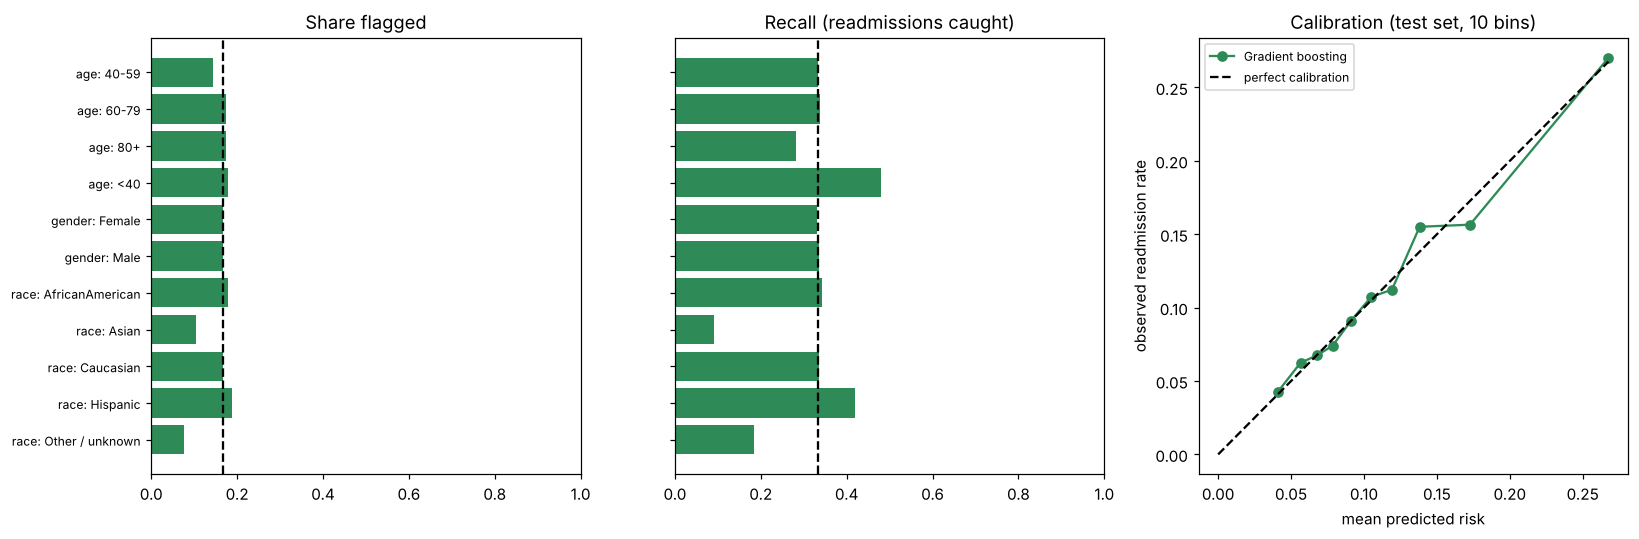

In [24]:
plot_data = subgroups.loc[["age", "gender", "race"]].reset_index()
labels = plot_data["dimension"] + ": " + plot_data["group"]
positions = np.arange(len(plot_data))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
# flagged share by group (dashed line = overall)
axes[0].barh(positions, plot_data["flagged share"], color=colors[selected])
axes[0].axvline(flagged_test.mean(), color="black", linestyle="--")
axes[0].set_title("Share flagged")
# recall by group (dashed line = overall)
axes[1].barh(positions, plot_data["recall"], color=colors[selected])
axes[1].axvline(operating_table.loc[selected + ": cost-optimal threshold", "recall"], color="black", linestyle="--")
axes[1].set_title("Recall (readmissions caught)")
for ax in axes[:2]:
    ax.set_yticks(positions)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
axes[0].set_yticklabels(labels, fontsize=8)
axes[1].set_yticklabels([])

# calibration: predicted risk vs. observed rate in 10 groups of equal size
observed, predicted = calibration_curve(y_test, probabilities_test, n_bins=10, strategy="quantile")
axes[2].plot(predicted, observed, marker="o", color=colors[selected], label=selected)
axes[2].plot([0, predicted.max()], [0, predicted.max()], color="black", linestyle="--", label="perfect calibration")
axes[2].set(xlabel="mean predicted risk", ylabel="observed readmission rate", title="Calibration (test set, 10 bins)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 5.2 What drives the predictions?

**Logistic regression coefficients.** The columns are standardized, so a coefficient shows how the log-odds change for one standard deviation. Positive means higher risk, negative means lower risk.

Non-zero coefficients: 59 out of 101


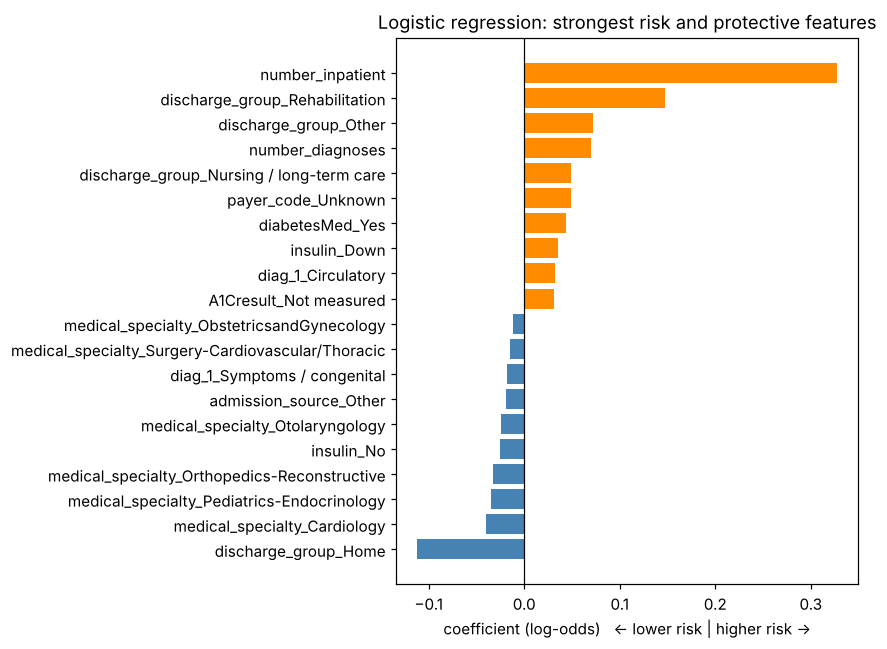

In [25]:
coefficients = pd.Series(model_logit.coef_[0], index=X_train.columns).sort_values()
print("Non-zero coefficients:", (coefficients != 0).sum(), "out of", len(coefficients))

top = pd.concat([coefficients.head(10), coefficients.tail(10)])          # 10 most protective and 10 strongest risk factors
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["steelblue" if v < 0 else "darkorange" for v in top.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("coefficient (log-odds)   <- lower risk | higher risk ->")
plt.title("Logistic regression: strongest risk and protective features")
plt.tight_layout()
plt.show()

**Which kind of information matters?** We sort the features into groups. On one held-out fold of the *training* data, we shuffle all columns of one group together and see how much the AUPRC drops. A bigger drop means the model relies more on that group.

Gradient boosting - AUPRC on the held-out fold: 0.2489


,AUPRC drop,SD
feature group,,
Prior visits,0.0995,0.0031
Current stay,0.0454,0.0019
Admission,0.0108,0.0021
Diagnosis,0.0084,0.0020
Medication,0.0044,0.0015
Demographics,0.0038,0.0029
Lab tests,0.0008,0.0005


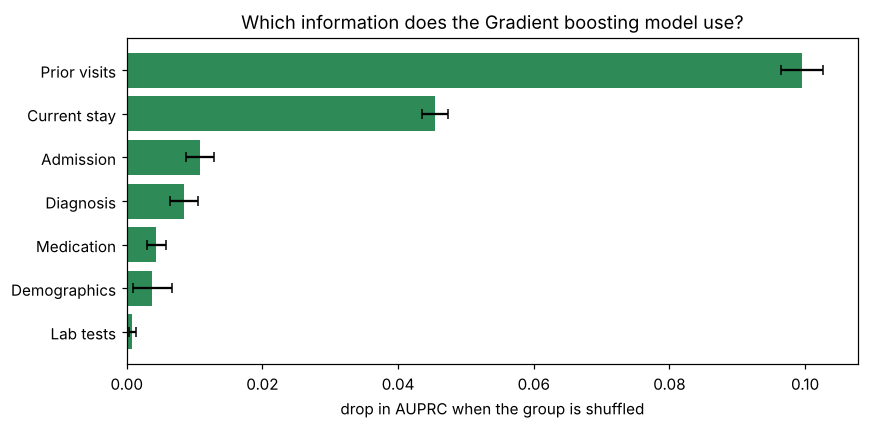

In [26]:
# feature groups: the variables that belong to each kind of information (race is not a model input)
feature_groups = {
    "Demographics":  ["age_num", "gender"],
    "Admission":     ["admission_type", "admission_source", "payer_code", "medical_specialty"],
    "Prior visits":  ["number_outpatient", "number_emergency", "number_inpatient"],
    "Current stay":  ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses", "discharge_group"],
    "Diagnosis":     ["diag_1"],
    "Lab tests":     ["max_glu_serum", "A1Cresult"],
    "Medication":    ["insulin", "change", "diabetesMed"],
}
# the columns of X that belong to each group (dummy columns start with the variable name)
group_columns = {g: [c for c in X_train.columns if c.startswith(tuple(variables))] for g, variables in feature_groups.items()}
assert sum(len(cols) for cols in group_columns.values()) == X_train.shape[1]       # every column is in exactly one group

fold_train, fold_val = next(cv.split(X_train, y_train, groups_train))        # first CV fold
X_in = inputs_train[selected]

model_check = clone(final_models[selected])
model_check.fit(X_in.iloc[fold_train], y_train[fold_train])
X_val, y_val = X_in.iloc[fold_val], y_train[fold_val]
base_auprc = average_precision_score(y_val, model_check.predict_proba(X_val)[:, 1])
print(selected, "- AUPRC on the held-out fold:", round(base_auprc, 4))

rows = []
for group, cols in group_columns.items():
    drops = []
    for repetition in range(5):
        X_shuffled = X_val.copy()
        X_shuffled[cols] = X_val[cols].sample(frac=1, random_state=repetition).to_numpy()      # shuffle the rows of the whole group together
        drops.append(base_auprc - average_precision_score(y_val, model_check.predict_proba(X_shuffled)[:, 1]))
    rows.append({"feature group": group, "AUPRC drop": np.mean(drops), "SD": np.std(drops, ddof=1)})
group_importance = pd.DataFrame(rows).set_index("feature group").sort_values("AUPRC drop")

plt.figure(figsize=(8, 4))
plt.barh(group_importance.index, group_importance["AUPRC drop"], xerr=group_importance["SD"], color=colors[selected], capsize=3)
plt.xlabel("drop in AUPRC when the group is shuffled")
plt.title("Which information does the " + selected + " model use?")
plt.tight_layout()
plt.show()
group_importance.sort_values("AUPRC drop", ascending=False).round(4)

### 5.3 Limits

- **Weak signal.** The model ranks patients better than chance and better than the clinical rule, but most flagged patients are not readmitted. It can help to prioritise follow-up, not to decide alone.
- **Old US data** (1999–2008). We could not test over time, because there are no admission dates.
- **Readmissions elsewhere are invisible.** A patient who returns to another hospital counts as "not readmitted".
- **Diagnosis codes** are often completed after discharge. If they are not available at discharge, this feature must be removed.
- **Several encounters per patient.** Frequent patients have more weight in the model.
- **Fairness.** Race is not an input, but other columns (payer, specialty) can act as proxies. Table 12 shows errors by group.
- **The costs are assumptions** (`cost_ratio`, `flag_share`). The hospital must set them.

**Before using it:** test it on recent local data, check errors by group again, and run a pilot where a random half of the flagged patients get the follow-up.